In [11]:
from bs_model import bs_call
import numpy as np
import pandas as pd

In [ ]:
# Model parameters
S0 = 100
K = 100
T = 1
r = 0.04
sigma = 0.20

# Number of simulations
N = 100_000

# Random number generator
rng = np.random.default_rng(42)

# Generate standard normal random variables
Z = rng.standard_normal(N)

# Simulate terminal stock prices
ST = S0 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z
)

print("First five simulated prices:")
print(ST[:5])


First five simulated prices:
[108.43095402  82.86173412 118.54118171 123.13522347  69.05913374]


In [4]:

# Theoretical expected terminal stock price
theoretical_mean = S0 * np.exp(r * T)

# Monte Carlo sample mean
simulated_mean = np.mean(ST)

# Difference between simulation and theory
difference = simulated_mean - theoretical_mean

print(f"Theoretical mean: ${theoretical_mean:.4f}")
print(f"Simulated mean:   ${simulated_mean:.4f}")
print(f"Difference:       ${difference:.4f}")


Theoretical mean: $104.0811
Simulated mean:   $104.0096
Difference:       $-0.0715


In [5]:

# Standard error of simulated mean
SE = np.std(ST, ddof=1) / np.sqrt(N)

# Standardized difference
z = difference / SE

print(f"Monte Carlo SE: ${SE:.4f}")
print(f"Standardized difference: {z:.3f}")

if abs(z) <= 1.96:
    print("PASS: Consistent with theoretical expectation")
else:
    print("CHECK: Difference exceeds approximate 95% range")


Monte Carlo SE: $0.0668
Standardized difference: -1.071
PASS: Consistent with theoretical expectation


In [ ]:
# Theoretical variance of the terminal stock price (lognormal)
theoretical_var = S0**2 * np.exp(2 * r * T) * (np.exp(sigma**2 * T) - 1)

# Monte Carlo sample variance
simulated_var = np.var(ST, ddof=1)

# Relative difference
rel_diff = (simulated_var - theoretical_var) / theoretical_var

print(f"Theoretical variance: {theoretical_var:.4f}")
print(f"Simulated variance:   {simulated_var:.4f}")
print(f"Relative difference:  {rel_diff:.4%}")

if abs(rel_diff) < 0.02:
    print("PASS: Variance consistent with theory (within 2%)")
else:
    print("CHECK: Variance differs from theory by more than 2%")

In [6]:

# Calculate call payoffs at expiration
payoffs = np.maximum(ST - K, 0)

# Discount the average payoff to present value
mc_price = np.exp(-r * T) * np.mean(payoffs)

print(f"Monte Carlo Call Price: ${mc_price:.4f}")


Monte Carlo Call Price: $9.8969


In [7]:

# Step 3: Calculate Monte Carlo option price

# Calculate the payoff for each simulated terminal stock price
payoffs = np.maximum(ST - K, 0)

# Discount each payoff to today's value
discounted_payoffs = np.exp(-r * T) * payoffs

# Calculate the Monte Carlo estimate
mc_price = np.mean(discounted_payoffs)

print(f"Monte Carlo Call Price: ${mc_price:.4f}")


Monte Carlo Call Price: $9.8969


In [8]:

# Calculate Monte Carlo standard error
mc_se = np.std(discounted_payoffs, ddof=1) / np.sqrt(N)

# Calculate approximate 95% confidence interval
ci_lower = mc_price - 1.96 * mc_se
ci_upper = mc_price + 1.96 * mc_se

print(f"Monte Carlo estimate: ${mc_price:.4f}")
print(f"Standard error:       ${mc_se:.4f}")
print(f"95% CI:               [${ci_lower:.4f}, ${ci_upper:.4f}]")


Monte Carlo estimate: $9.8969
Standard error:       $0.0458
95% CI:               [$9.8070, $9.9867]


In [9]:

from bs_model import bs_call

# Analytical Black-Scholes price
bs_price = bs_call(S0, K, T, r, sigma)

# Difference
pricing_error = mc_price - bs_price

# Check whether analytical benchmark lies within MC interval
within_ci = ci_lower <= bs_price <= ci_upper

print(f"Black-Scholes price:  ${bs_price:.4f}")
print(f"Monte Carlo price:    ${mc_price:.4f}")
print(f"Difference (MC - BS): ${pricing_error:.4f}")
print(f"BS within 95% MC CI:  {within_ci}")


Black-Scholes price:  $9.9251
Monte Carlo price:    $9.8969
Difference (MC - BS): $-0.0282
BS within 95% MC CI:  True


In [10]:
from bs_model import bs_call

bs_price = bs_call(S0, K, T, r, sigma)

difference = mc_price - bs_price
z_score = difference / mc_se

print(f"BS Price:       ${bs_price:.4f}")
print(f"MC Price:       ${mc_price:.4f}")
print(f"Pricing Error:  ${difference:.4f}")
print(f"Z-score:        {z_score:.3f}")

if ci_lower <= bs_price <= ci_upper:
    print("PASS: BS price falls within Monte Carlo 95% CI")
else:
    print("CHECK: BS price falls outside Monte Carlo 95% CI")


BS Price:       $9.9251
MC Price:       $9.8969
Pricing Error:  $-0.0282
Z-score:        -0.615
PASS: BS price falls within Monte Carlo 95% CI


In [12]:
strikes = [90, 100, 110]
results = []

for strike in strikes:

    # 1. Calculate option payoffs
    payoffs = np.maximum(ST - strike, 0)

    # 2. Discount payoffs
    discounted_payoffs = np.exp(-r * T) * payoffs

    # 3. Monte Carlo price
    mc_price = np.mean(discounted_payoffs)

    # 4. Monte Carlo standard error
    mc_se = (
        np.std(discounted_payoffs, ddof=1)
        / np.sqrt(N)
    )

    # 5. 95% confidence interval
    ci_lower = mc_price - 1.96 * mc_se
    ci_upper = mc_price + 1.96 * mc_se

    # 6. Analytical Black-Scholes benchmark
    bs_price = bs_call(S0, strike, T, r, sigma)

    # 7. Pricing difference
    error = mc_price - bs_price

    # 8. Store results
    results.append({
        "Strike": strike,
        "BS Price": bs_price,
        "MC Price": mc_price,
        "Error": error,
        "MC SE": mc_se,
        "CI Lower": ci_lower,
        "CI Upper": ci_upper,
        "Within CI": ci_lower <= bs_price <= ci_upper
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


 Strike  BS Price  MC Price   Error  MC SE  CI Lower  CI Upper  Within CI
     90   16.0604   16.0185 -0.0420 0.0545   15.9116   16.1253       True
    100    9.9251    9.8969 -0.0282 0.0458    9.8070    9.9867       True
    110    5.6588    5.6606  0.0018 0.0360    5.5901    5.7310       True


### Financial consistency tests

#### Test A: Call price decreases as strike increases

In [14]:

prices = [
    bs_call(S0, strike, T, r, sigma)
    for strike in strikes
]

assert prices[0] >= prices[1] >= prices[2]

print("PASS: Call price decreases with strike.")


PASS: Call price decreases with strike.


#### Test B: Call price increases with volatility

In [15]:

volatilities = [0.10, 0.20, 0.30]

vol_prices = [
    bs_call(S0, 100, T, r, vol)
    for vol in volatilities
]

assert vol_prices[0] < vol_prices[1] < vol_prices[2]

print("PASS: Call price increases with volatility.")


PASS: Call price increases with volatility.


#### Test C: No-arbitrage price bounds

In [16]:

for strike in strikes:

    price = bs_call(S0, strike, T, r, sigma)

    lower = max(S0 - strike * np.exp(-r * T), 0)
    upper = S0

    assert lower <= price <= upper

print("PASS: All call prices satisfy no-arbitrage bounds.")


PASS: All call prices satisfy no-arbitrage bounds.


#### Tests A-C on Monte Carlo prices (common random numbers)

The tests above check the Black-Scholes formula. The cells below run the same tests on the **Monte Carlo** prices.
Every price reuses the same draws `Z`, so differences between prices come from the strike or volatility, not from simulation noise.

In [ ]:
# Reusable helpers

def simulate_ST(S0, T, r, sigma, Z):
    """Risk-neutral GBM terminal prices from standard normal draws Z."""
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)


def mc_call(ST, K, T, r):
    """Monte Carlo call price and its standard error."""
    discounted_payoffs = np.exp(-r * T) * np.maximum(ST - K, 0)
    price = np.mean(discounted_payoffs)
    se = np.std(discounted_payoffs, ddof=1) / np.sqrt(len(discounted_payoffs))
    return price, se

In [ ]:
# Test A (MC): call price decreases as strike increases
mc_strike_prices = [mc_call(ST, strike, T, r)[0] for strike in strikes]

assert mc_strike_prices[0] > mc_strike_prices[1] > mc_strike_prices[2]
print("PASS (MC): Call price decreases with strike:",
      [round(float(p), 4) for p in mc_strike_prices])

In [ ]:
# Test B (MC): call price increases with volatility (same Z for every sigma)
mc_vol_prices = [
    mc_call(simulate_ST(S0, T, r, vol, Z), 100, T, r)[0]
    for vol in volatilities
]

assert mc_vol_prices[0] < mc_vol_prices[1] < mc_vol_prices[2]
print("PASS (MC): Call price increases with volatility:",
      [round(float(p), 4) for p in mc_vol_prices])

In [ ]:
# Test C (MC): no-arbitrage bounds
for strike, price in zip(strikes, mc_strike_prices):
    lower = max(S0 - strike * np.exp(-r * T), 0)
    upper = S0
    assert lower <= price <= upper, f"Bound violated at K={strike}"

print("PASS (MC): All Monte Carlo prices satisfy no-arbitrage bounds.")

### Monte Carlo comparison figure

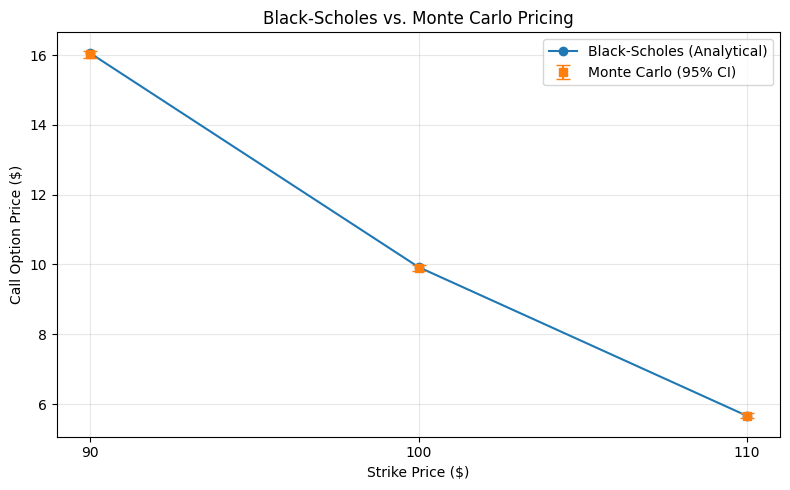

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Analytical Black-Scholes prices
plt.plot(
    results_df["Strike"],
    results_df["BS Price"],
    "o-",
    label="Black-Scholes (Analytical)"
)

# Monte Carlo prices with 95% confidence intervals
plt.errorbar(
    results_df["Strike"],
    results_df["MC Price"],
    yerr=1.96 * results_df["MC SE"],
    fmt="s",
    capsize=5,
    label="Monte Carlo (95% CI)"
)

plt.xlabel("Strike Price ($)")
plt.ylabel("Call Option Price ($)")
plt.title("Black-Scholes vs. Monte Carlo Pricing")

plt.xticks(strikes)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("mc_verification.png", dpi=300)
plt.show()


In [17]:

print("BASELINE MODEL VALIDATION SUMMARY")
print("--------------------------------")

print(f"Number of simulations: {N:,}")
print(f"Strikes tested: {strikes}")
print(f"Maximum absolute pricing error: "
      f"${results_df['Error'].abs().max():.4f}")

print(f"Analytical benchmarks within individual 95% CIs: "
      f"{results_df['Within CI'].sum()} / {len(strikes)}")

print("Financial consistency tests: See test results above.")


BASELINE MODEL VALIDATION SUMMARY
--------------------------------
Number of simulations: 100,000
Strikes tested: [90, 100, 110]
Maximum absolute pricing error: $0.0420
Analytical benchmarks within individual 95% CIs: 3 / 3
Financial consistency tests: See test results above.


## Phase 3: Two-regime volatility experiment

The market is low-vol (10%) or high-vol (30%) with probability 1/2 each, and the regime stays fixed for the whole path.
We simulate exactly half the paths in each regime (stratified sampling), so the mixture price is the average of the two regime prices.

**Validation check:** because each regime is plain GBM, the exact answer is
$C_{mix} = \tfrac12 C_{BS}(10\%) + \tfrac12 C_{BS}(30\%)$. The Monte Carlo price should fall inside its 95% CI around this value.

In [ ]:
# Regime parameters
sigma_low = 0.10
sigma_high = 0.30
p_low = 0.5

# Independent draws for each regime, half the paths each
rng_mix = np.random.default_rng(2026)
N_half = N // 2
Z_low = rng_mix.standard_normal(N_half)
Z_high = rng_mix.standard_normal(N_half)

ST_low = simulate_ST(S0, T, r, sigma_low, Z_low)
ST_high = simulate_ST(S0, T, r, sigma_high, Z_high)

mixture_results = []

for strike in strikes:

    # Price in each regime
    price_low, se_low = mc_call(ST_low, strike, T, r)
    price_high, se_high = mc_call(ST_high, strike, T, r)

    # Mixture price: weighted average of the two regimes
    mc_price_mix = p_low * price_low + (1 - p_low) * price_high

    # Independent halves, so the variances add
    mc_se_mix = np.sqrt((p_low * se_low)**2 + ((1 - p_low) * se_high)**2)

    ci_lower = mc_price_mix - 1.96 * mc_se_mix
    ci_upper = mc_price_mix + 1.96 * mc_se_mix

    # Exact mixture price (analytical check)
    exact_mix = (p_low * bs_call(S0, strike, T, r, sigma_low)
                 + (1 - p_low) * bs_call(S0, strike, T, r, sigma_high))

    mixture_results.append({
        "Strike": strike,
        "MC Price": mc_price_mix,
        "MC SE": mc_se_mix,
        "CI Lower": ci_lower,
        "CI Upper": ci_upper,
        "Exact Mixture Price": exact_mix,
        "Error": mc_price_mix - exact_mix,
        "Within CI": ci_lower <= exact_mix <= ci_upper,
    })

mixture_df = pd.DataFrame(mixture_results)
print(mixture_df.round(4).to_string(index=False))

In [ ]:
# Figure: exact mixture price vs Monte Carlo benchmark
plt.figure(figsize=(8, 5))

plt.plot(
    mixture_df["Strike"],
    mixture_df["Exact Mixture Price"],
    "o-",
    label="Exact mixture: 0.5 BS(10%) + 0.5 BS(30%)"
)

plt.errorbar(
    mixture_df["Strike"],
    mixture_df["MC Price"],
    yerr=1.96 * mixture_df["MC SE"],
    fmt="s",
    capsize=5,
    label="Monte Carlo benchmark (95% CI)"
)

plt.xlabel("Strike Price ($)")
plt.ylabel("Call Option Price ($)")
plt.title("Two-Regime Market: Monte Carlo Benchmark Prices")
plt.xticks(strikes)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("mc_two_regime.png", dpi=300)
plt.show()

## Phase 4: Final results

In [ ]:
# Export results tables
results_df.to_csv("baseline_results.csv", index=False)
mixture_df.to_csv("two_regime_results.csv", index=False)

print("Saved: baseline_results.csv, two_regime_results.csv")
print("Saved: mc_verification.png, mc_two_regime.png")

In [ ]:
print("TWO-REGIME BENCHMARK SUMMARY")
print("----------------------------")
print(f"Paths per regime: {N_half:,} (total {N:,})")
print(f"Regimes: sigma = {sigma_low:.0%} and {sigma_high:.0%}, probability {p_low:.0%} each")
print(f"Maximum absolute error vs exact mixture: "
      f"${mixture_df['Error'].abs().max():.4f}")
print(f"Exact mixture prices within 95% CIs: "
      f"{mixture_df['Within CI'].sum()} / {len(strikes)}")